# SVT hit filtering with machine learning

**Goal.** Remove background SVT hits *before* Kalman pattern recognition, so that tracks pick up fewer wrong hits
— without losing good tracks. The filter must be trainable on MC and on real data, and it must run inside hps-java as
a driver that is inserted by editing the steering file.

**Where it runs.**

```
RawTrackerHitFitterDriver → (MC: RawHitTimeSmearer) → TrackerHitDriver [strip clustering]
   → (MC: StripHitKiller, StripHitNHitsSmearer) → SvtHitFilterDriver → KalmanPatRecDriver → ...
```

`SvtHitFilterDriver` (in `hps-java/`) scores every strip cluster in `StripClusterer_SiTrackerHitStrip1D` and
replaces that collection in place with the clusters that pass, the same way `StripHitKiller` works. The Kalman
driver, which reads this collection by a fixed name, needs no change.

**Contents**

1. Choice of the model
2. Features
3. Data sets
4. Benchmark of the models on MC truth (hit level and track level)
5. Working point: no loss of good tracks
6. Real data: why direct training fails, data/MC comparison, fine-tuning on data, validation on data
7. Beyond pre-filtering: hits on tracks (stage 2)
8. Export, Java parity test and steering
9. Summary and next steps

Previous notebooks: `../Tracking_Efficiency_SVT_Hits.ipynb` (efficiency and hits) and
`../Tracking_Efficiency_by_Charge_and_Half.ipynb` (charge and half). Reusable code: `Analysis/svt_hitfilter.py` and
`svt_hitfilter.h` (features), `Analysis/svt_tracking.py`.

## 1. Choice of the model

What a hit filter can know before tracking:
- the hit itself: time, charge, cluster size, sensor, position;
- its neighbourhood in the same event: other hits that could belong to the same track.

The geometry decides how to use the neighbourhood. The field is vertical, so in the non-bend (y–z) plane a primary
track is a straight line from the target: hits of one track share tan λ = y / (z − z_target). Only the axial strips
measure y precisely; each module pairs an axial with a stereo sensor about 8 mm apart. Background is concentrated in
L1–L4, close to the beam plane, and is spread uniformly over the ±75 ns readout window.

| approach | time / charge | geometric context | labels needed | in hps-java | assessment |
|---|---|---|---|---|---|
| hit-time window | time only | no | none | trivial | baseline |
| convolutional auto-encoder (CLAS12 drift chambers, arXiv:2205.02616) | no (occupancy image) | yes, as an image | hits on data tracks | needs a DL runtime | made for a dense, regular wire grid where track segments are local line patterns. HPS has 1D strips on sensors of different size and pitch, hole/slot sensors and stereo layers, and its strongest variable, time, is not part of an image |
| graph neural network (Exa.TrkX-type edge/node classification) | yes | learned | MC truth | ONNX Runtime or DJL (native libraries) | most flexible. With ~70 hits per half-event in 14 layers, the useful context is "is there a time-compatible, target-pointing set of hits in other modules", which can be computed explicitly. Harder to train, deploy and validate on data |
| MLP on engineered features | yes | engineered | MC truth | easy (matrix products) | benchmarked below |
| **gradient-boosted trees (GBDT) on per-hit + engineered context features** | yes | engineered | MC truth | **plain Java, no dependencies** | standard for tabular, mixed-type features. Monotonic constraints make it robust where data and MC differ; ~µs per hit; interpretable. **Chosen** |

The context features below act like one round of message passing in a GNN, with the messages written by hand.
§4 tests whether the context, and a neural network instead of trees, actually help.

In [1]:
import os, sys, time, subprocess
sys.path.insert(0, "../..")                       # the Analysis package lives at the repository root
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.metrics import roc_auc_score
from Analysis import svt_tracking as st, svt_hitfilter as hf

hf.setup(n_threads=32)
st.mpl_style()
C = st.COLORS
FI = {f: i for i, f in enumerate(hf.FEATURES)}

MC_FILES = st.SAMPLES["overlay"].files()          # tritrig + pulser overlay (truth for every hit)
TRAIN, CTRL, TEST = MC_FILES[0:40], MC_FILES[40:100], MC_FILES[500:530]
PURE_FILES = st.SAMPLES["pure"].files()[0:60]     # tritrig without overlay: the simulation reference for data/MC
DATA_FILES = st.DATA["run14229"].files()          # run 14229, pass5_v9, unskimmed
MAX_LOST = 0.003                                  # working point: at most 0.3 % of found particles become unfindable
OUT = "models"
os.makedirs(OUT, exist_ok=True)

## 2. Features

27 features per strip cluster, computed per event by `svt::hf::features()` (C++, used for training) and by
`SvtHitFilterFeatures.java` (used by the driver), with identical definitions. Times are relative to the signal time
t0 of the data set (MC overlay −0.1 ns, run 14229 +0.4 ns, from the hits on good tracks).

In [2]:
pd.DataFrame({"feature": hf.FEATURES, "definition": [hf.FEATURE_DOC[f] for f in hf.FEATURES],
              "monotonic constraint": [{1: "increasing", -1: "decreasing"}.get(hf.MONOTONE.get(f, 0), "") for f in hf.FEATURES]}
            ).set_index("feature")

,definition,monotonic constraint
feature,,
layer,SVT layer 1-14,
top,1 = top half,
stereo,1 = stereo sensor,
side,1 = positron-side sensor (L9-L14),
t,hit time - t0 [ns],
q,cluster charge (edep x 1e6),
nstrip,strips in the cluster,
absy,|y| [mm],
tl,"y/(z - zT), > 0 away from the beam plane",


## 3. Data sets

| name | content | use |
|---|---|---|
| `mc_tr` | overlay MC, files 0–39 | training (truth: hit has an MC particle = signal) |
| `mc_te` | overlay MC, files 500–529 | test: hit-level and track-level evaluation |
| `mc_phys`, `mc_puls` | overlay MC files 40–99; even events as they are ("physics"), odd events with all MC hits removed ("pulser") | emulate data-style training with known truth; `mc_puls` is real pulser data (run-14272 headers), compared with the run-14229 pulser data in §6b |
| `mc_pure` | pure tritrig MC (no overlay), files 0–59 | **simulation reference** for the data/MC comparison of signal hits (§6b) |
| `d_puls` | run 14229, **pulser triggers** (TS bit 15) from all 45 files | background in data (pure, random trigger) |
| `d_phys_a`, `d_phys` | run 14229, physics triggers, files 1 and 0 | data control sample for fine-tuning (file 1) and evaluation (file 0) |

**Which MC is "MC".** In the overlay MC only the signal hits are simulated; every background hit *is* real
pulser data. Comparing data with the overlay MC therefore measures the simulation only through the signal hits,
and comparing overlaid background with data compares data with data. The data/MC comparison of the hit response
(§6b) uses the pure MC as the reference.

*Golden tracks* (signal tag in data and MC): in time (±3 ns), ≥ 12 hits, χ²/ndf < 3, p > 1 GeV, linked to an ECal
cluster.

In [3]:
t_start = time.time()
TP = ["tp_idx", "tp_found", "tp_acc", "tp_top", "tp_pos", "tp_layers", "tp_n_layers"]
MCH = ("hf_is_mc", "hf_prim", "hf_code", "hf_on_golden", "hf_golden_trk")
DH = ("hf_on_track", "hf_on_golden", "hf_golden_trk")
mc_tr = hf.collect(hf.mc_frame("overlay", TRAIN), per_hit=MCH, track_rows=True)
mc_te = hf.collect(hf.mc_frame("overlay", TEST), per_hit=MCH, per_particle=TP, track_rows=True)
mc_phys = hf.collect(hf.mc_frame("overlay", CTRL, parity=0), per_hit=MCH)
mc_puls = hf.collect(hf.mc_frame("overlay", CTRL, drop_mc=True, parity=1), per_hit=MCH)
mc_pure = hf.collect(hf.mc_frame("pure", PURE_FILES), per_hit=MCH)
d_puls = hf.collect(hf.data_frame("run14229", DATA_FILES, "pulser"), per_hit=DH)
d_phys_a = hf.collect(hf.data_frame("run14229", DATA_FILES[1:2], "physics"), per_hit=DH)
d_phys = hf.collect(hf.data_frame("run14229", DATA_FILES[0:1], "physics"), per_hit=DH)
d_gold_a = d_phys_a["X"][d_phys_a["on_golden"] == 1]       # only the golden hits of the control file are needed
del d_phys_a

sets = {"mc_tr": mc_tr, "mc_te": mc_te, "mc_phys": mc_phys, "mc_puls": mc_puls, "mc_pure": mc_pure, "d_puls": d_puls, "d_phys": d_phys}
print(f"Read in {time.time() - t_start:.0f} s")
pd.DataFrame({k: {"events": v["n_events"], "hits": len(v["X"]), "hits / event": len(v["X"]) / v["n_events"],
                  "signal fraction (MC truth)": v["is_mc"].mean() if "is_mc" in v else np.nan}
              for k, v in sets.items()}).T.round(3)

Read in 178 s


,events,hits,hits / event,signal fraction (MC truth)
mc_tr,65944.0,9097772.0,137.962,0.131
mc_te,49656.0,6819846.0,137.342,0.131
mc_phys,49809.0,6388585.0,128.262,0.141
mc_puls,49930.0,5481442.0,109.783,0.000
mc_pure,126581.0,2311785.0,18.263,1.000
d_puls,17335.0,2076620.0,119.793,NaN
d_phys,143057.0,19294441.0,134.872,NaN


### Feature distributions

Five samples, distinguished by colour:
- simulated signal: **pure MC** (all hits) and **overlay MC** (hits with MC truth, i.e. with the real background
  around them);
- **overlay background**: the overlaid pulser-data hits (real data, run-14272 headers);
- run 14229: **golden-track hits** (signal proxy) and **pulser-trigger hits** (background).

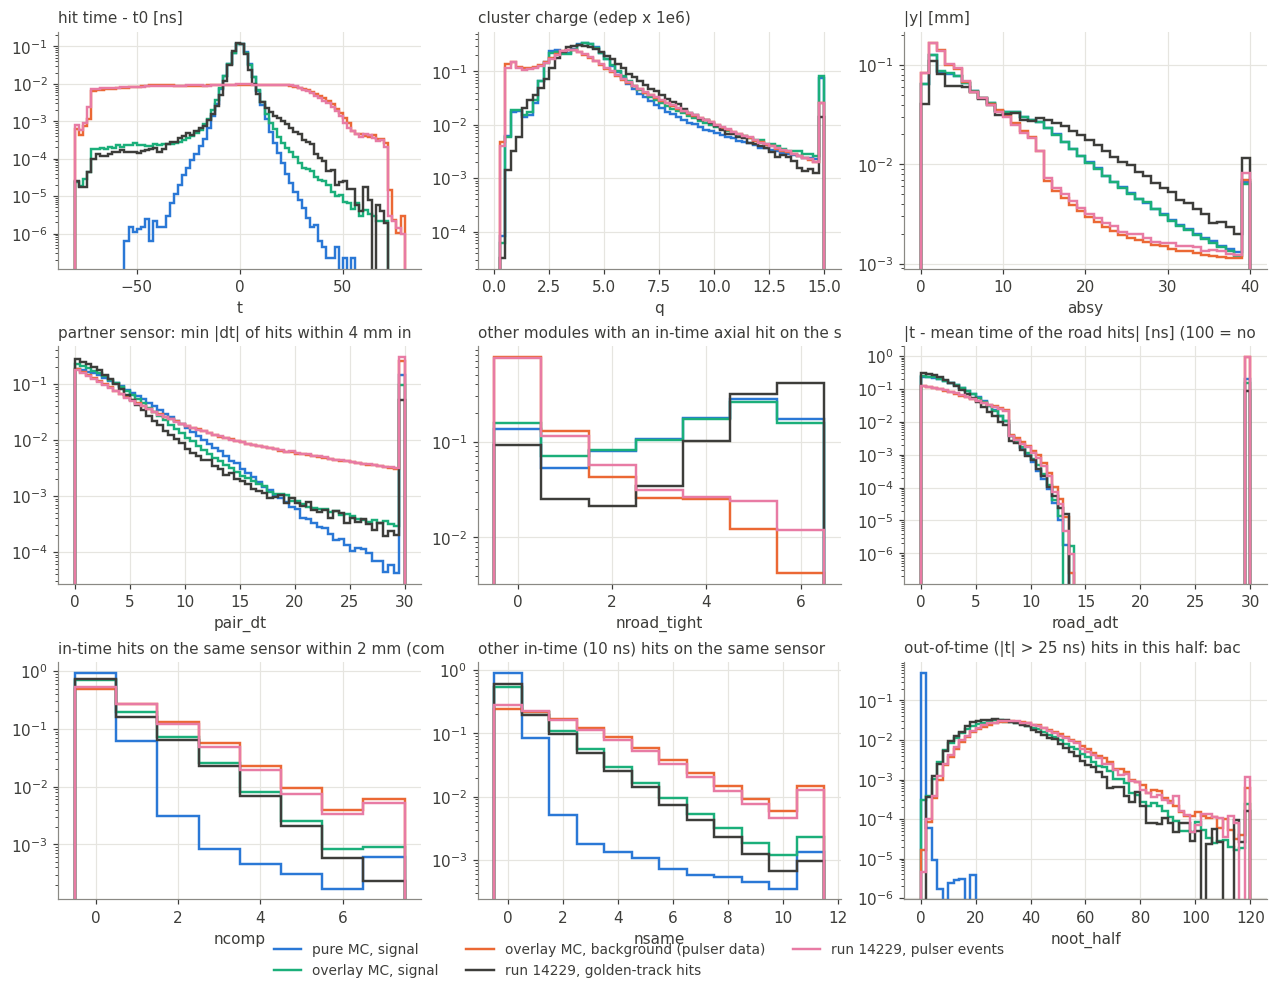

In [4]:
show = ["t", "q", "absy", "pair_dt", "nroad_tight", "road_adt", "ncomp", "nsame", "noot_half"]
bins = {"t": np.linspace(-80, 80, 81), "q": np.linspace(0, 15, 61), "absy": np.linspace(0, 40, 41),
        "pair_dt": np.linspace(0, 30, 61), "nroad_tight": np.arange(-0.5, 7), "road_adt": np.linspace(0, 30, 61),
        "ncomp": np.arange(-0.5, 8), "nsame": np.arange(-0.5, 12), "noot_half": np.linspace(0, 120, 61)}
sig, bkg = mc_tr["is_mc"] == 1, mc_tr["is_mc"] == 0
gold = d_phys["on_golden"] == 1
# colour = sample; data in dark ink (convention), its background in magenta
SC = {"pure MC, signal": C["pure"], "overlay MC, signal": C["third"], "overlay MC, background (pulser data)": C["overlay"],
      "run 14229, golden-track hits": C["ink"], "run 14229, pulser events": "#e87ba4"}
samples5 = ((mc_pure["X"], mc_pure["is_mc"] == 1), (mc_tr["X"], sig), (mc_tr["X"], bkg), (d_phys["X"], gold), (d_puls["X"], slice(None)))
fig, axes = plt.subplots(3, 3, figsize=(11.5, 8.6))
for ax, f in zip(axes.flat, show):
    i, b = FI[f], bins[f]
    for (X, m), (lab, col) in zip(samples5, SC.items()):
        h, _ = np.histogram(np.clip(X[m, i], b[0], b[-1] - 1e-6), bins=b, density=True)
        ax.stairs(h, b, color=col, lw=1.6, label=lab)
    ax.set_yscale("log")
    st.style(ax, f, None, hf.FEATURE_DOC[f][:48], legend=False)
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.show()

- **Time is the strongest single variable.** Signal hits peak within a few ns; background is flat over the
  readout window.
- **The time tail of signal hits comes from the background, not the simulation.** Pure-MC hits have almost no
  tail beyond ±30 ns. In the overlay MC, signal hits that pile up with real background hits in the same strips get
  a tail out to −75 ns. Data golden-track hits have a similar but larger tail.
- **Context separates where time cannot.** A signal hit almost always has an in-time partner on the other sensor of
  its module (`pair_dt`) and several in-time axial hits on the same target-pointing line (`nroad_tight`: median 4–5
  for signal, 0 for background). Background hits sit closer to the beam plane (`absy`) and in busier sensors
  (`nsame`, `ncomp`).
- **Occupancy features have no meaning in the pure MC** (`nsame`, `ncomp`, `noot_half` ≈ 0 there), so the pure MC
  cannot be the reference for them (§6b).
- **The two pulser samples agree closely.** That is expected: both are real data, and only the run differs. For the
  signal, data golden-track hits are at larger |y| (a different physics mix: FEE and WAB) and have a broader charge
  distribution.

## 4. Benchmark on MC truth

Models, all trained on `mc_tr` (signal = hit with MC truth) and tested on `mc_te`:
- **time window** |t| < w (baseline);
- **GBDT, per-hit features** (layer, half, stereo, side, t, q, nstrip, |y|, tan λ);
- **GBDT + context** (all 27 features, with the monotonic constraints listed in §2);
- **GBDT + context, unconstrained**;
- **MLP + context**: 3 hidden layers (128, 128, 64), inputs Gaussianised with a quantile transform, trained on 2 M
  hits (scikit-learn, CPU).

Two figures of merit:
- *hit level*: fraction of background hits kept against fraction of signal hits lost;
- *track level*, which is what matters. "Lost tracks" are particles that the KF found and that are findable with all
  their hits, but are no longer findable with the kept hits. Findability uses an emulator of the KF requirements
  (hits, stereo and axial counts, seed patterns; checked on pure MC: 99.95 % of found particles are findable). This is
  set against the fraction of the **wrong hits on matched tracks** that the filter removes.

In [5]:
MONO = [hf.MONOTONE.get(f, 0) for f in hf.FEATURES]
PER_HIT = list(range(FI["tl"] + 1))
ALL = list(range(len(hf.FEATURES)))

def gbdt(mono=None, **kw):
    p = dict(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=200, l2_regularization=1.0,
             early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=1)
    p.update(kw)
    return HGB(monotonic_cst=mono, **p)

X, y = mc_tr["X"], mc_tr["is_mc"]
bench, fit_time = {}, {}
for name, cols, mono in (("GBDT, per-hit features", PER_HIT, None), ("GBDT + context", ALL, MONO),
                         ("GBDT + context, unconstrained", ALL, None)):
    t0 = time.time()
    m = gbdt(mono).fit(X[:, cols], y)
    fit_time[name] = time.time() - t0
    bench[name] = (m, cols)

# MLP (scikit-learn). TensorFlow is not used: importing it after ROOT's multithreaded RDataFrame crashes the kernel.
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import QuantileTransformer
rng = np.random.default_rng(1)
sub = rng.choice(len(X), 2_000_000, replace=False)
qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=1_000_000, random_state=1).fit(X[sub])
t0 = time.time()
mlp = MLPClassifier(hidden_layer_sizes=(128, 128, 64), batch_size=4096, learning_rate_init=1e-3, max_iter=12,
                    early_stopping=True, validation_fraction=0.05, n_iter_no_change=3, random_state=1)
mlp.fit(qt.transform(X[sub]), y[sub])
fit_time["MLP + context"] = time.time() - t0

scores = {name: m.predict_proba(mc_te["X"][:, cols])[:, 1] for name, (m, cols) in bench.items()}
scores["MLP + context"] = mlp.predict_proba(qt.transform(mc_te["X"]))[:, 1]
print("training time [s]:", {k: round(v) for k, v in fit_time.items()})

/net/data/endeavour2/Tools/miniconda3/envs/T/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (12) reached and the optimization hasn't converged yet.
  warnings.warn(


training time [s]: {'GBDT, per-hit features': 26, 'GBDT + context': 32, 'GBDT + context, unconstrained': 34, 'MLP + context': 47}


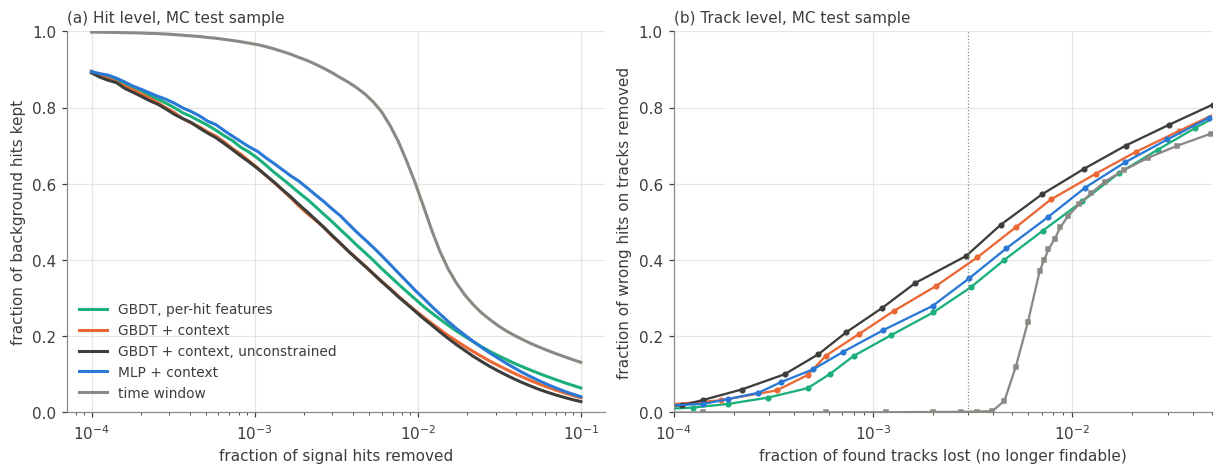

,AUC,training [s],wrong removed @ 0.1% lost,bkg kept @ 0.1% lost,wrong removed @ 0.3% lost,bkg kept @ 0.3% lost,wrong removed @ 1.0% lost,bkg kept @ 1.0% lost
"GBDT, per-hit features",0.976,26.343,0.173,0.526,0.323,0.371,0.531,0.217
GBDT + context,0.984,32.151,0.227,0.434,0.387,0.291,0.587,0.160
"GBDT + context, unconstrained",0.986,34.267,0.255,0.412,0.415,0.270,0.617,0.137
MLP + context,0.982,46.825,0.199,0.482,0.349,0.333,0.560,0.178
time window,NaN,0.000,0.001,0.916,0.002,0.797,0.527,0.275


In [6]:
yt = mc_te["is_mc"]
t_abs = np.abs(mc_te["X"][:, FI["t"]])
widths = np.r_[np.arange(4, 20, 1), np.arange(20, 80, 5)]
scan_t = hf.scan_time(mc_te, widths)
scans = {name: hf.scan(mc_te, s) for name, s in scores.items()}
MODEL_COLORS = {"time window": C["muted"], "GBDT, per-hit features": C["third"], "GBDT + context": C["overlay"],
                "GBDT + context, unconstrained": C["ink"], "MLP + context": C["pure"]}

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
sig_loss = np.geomspace(1e-4, 0.1, 60)
for name, s in scores.items():
    thr = np.quantile(s[yt == 1], sig_loss)
    a.plot(sig_loss, [(s[yt == 0] >= t_).mean() for t_ in thr], color=MODEL_COLORS[name], label=name)
thr_t = np.quantile(t_abs[yt == 1], 1 - sig_loss)
a.plot(sig_loss, [(t_abs[yt == 0] <= w).mean() for w in thr_t], color=MODEL_COLORS["time window"], label="time window")
a.set_xscale("log"); a.set_ylim(0, 1)
st.style(a, "fraction of signal hits removed", "fraction of background hits kept", "(a) Hit level, MC test sample")
for name, sc in scans.items():
    b.plot(sc["lost"], sc["wrong_removed"], "o-", ms=3, lw=1.5, color=MODEL_COLORS[name], label=name)
b.plot(scan_t["lost"], scan_t["wrong_removed"], "s-", ms=3, lw=1.5, color=MODEL_COLORS["time window"], label="time window")
b.axvline(MAX_LOST, color=C["muted"], lw=0.8, ls=":")
b.set_xscale("log"); b.set_xlim(1e-4, 0.05); b.set_ylim(0, 1)
st.style(b, "fraction of found tracks lost (no longer findable)", "fraction of wrong hits on tracks removed",
         "(b) Track level, MC test sample", legend=False)
plt.show()

def at_loss(sc, target, col):
    s = sc.sort_values("lost")
    return float(np.interp(target, s["lost"], s[col]))

rows = []
for name, sc in list(scans.items()) + [("time window", scan_t)]:
    r = {"AUC": roc_auc_score(yt, scores[name]) if name in scores else np.nan, "training [s]": fit_time.get(name, 0)}
    for tgt in (0.001, MAX_LOST, 0.01):
        r[f"wrong removed @ {tgt:.1%} lost"] = at_loss(sc, tgt, "wrong_removed")
        r[f"bkg kept @ {tgt:.1%} lost"] = at_loss(sc, tgt, "bkg_kept")
    rows.append(pd.Series(r, name=name))
pd.DataFrame(rows).round(3)

- **A time window is useless when no tracks may be lost.** To lose at most 0.3 % of the found tracks it must
  be ±48 ns wide. It then removes only 20 % of the background and 0.2 % of the wrong hits. Correct hits with badly
  measured times set this limit.
- **All learned models are far better.** At 0.3 % lost tracks, *GBDT + context* removes 39 % of the wrong hits on
  tracks and 71 % of the background hits.
- **Geometric context helps.** It adds 6–7 points of wrong-hit removal at fixed track loss over per-hit features
  (32 % → 39 %), and 8 points of background removal.
- **Trees beat the MLP** on the same inputs (MLP: 35 % / 67 %), train in 30 s and need no runtime library.
- **Monotonic constraints cost 2–3 points on MC** (unconstrained: 42 %). They are kept because they make the model
  behave sensibly where data and MC differ, which matters more (§6).

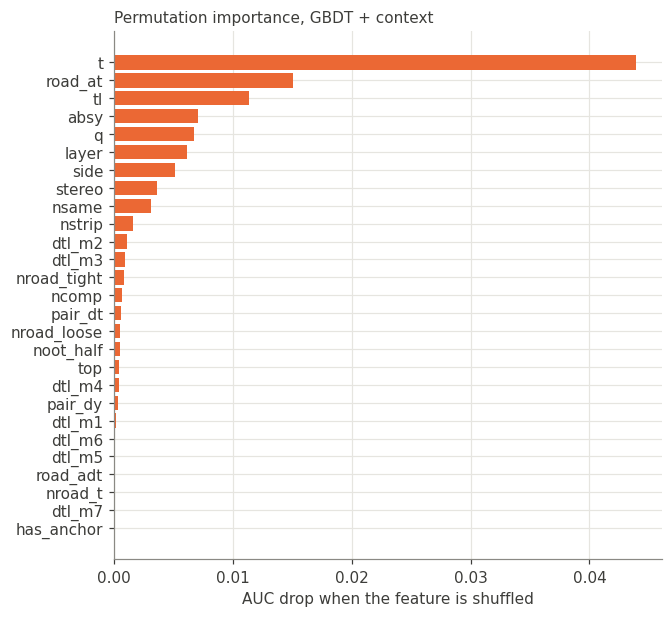

In [7]:
# Which features matter (permutation importance on 1 M test hits, drop in AUC)
m, cols = bench["GBDT + context"]
sub = np.random.default_rng(2).choice(len(mc_te["X"]), 1_000_000, replace=False)
Xs, ys = mc_te["X"][sub], yt[sub]
base_auc = roc_auc_score(ys, m.predict_proba(Xs)[:, 1])
imp = {}
for f in hf.FEATURES:
    Xp = Xs.copy(); Xp[:, FI[f]] = np.random.default_rng(3).permutation(Xp[:, FI[f]])
    imp[f] = base_auc - roc_auc_score(ys, m.predict_proba(Xp)[:, 1])
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.barh(imp.index, imp.values, color=C["overlay"])
st.style(ax, "AUC drop when the feature is shuffled", None, "Permutation importance, GBDT + context", grid=True)
plt.show()

Hit time dominates, followed by the time of the road (`road_at`), tan λ and |y|, charge and the sensor.
The individual context features rank low only because they are strongly correlated: shuffling one leaves the
others. As a group they are what moves the track-level curve in §4.

## 5. Working point: do not lose good tracks

The threshold is set on the test sample so that at most `MAX_LOST` (0.3 %) of the KF-found particles become
unfindable. The table and figure show what this costs and gains, layer by layer.

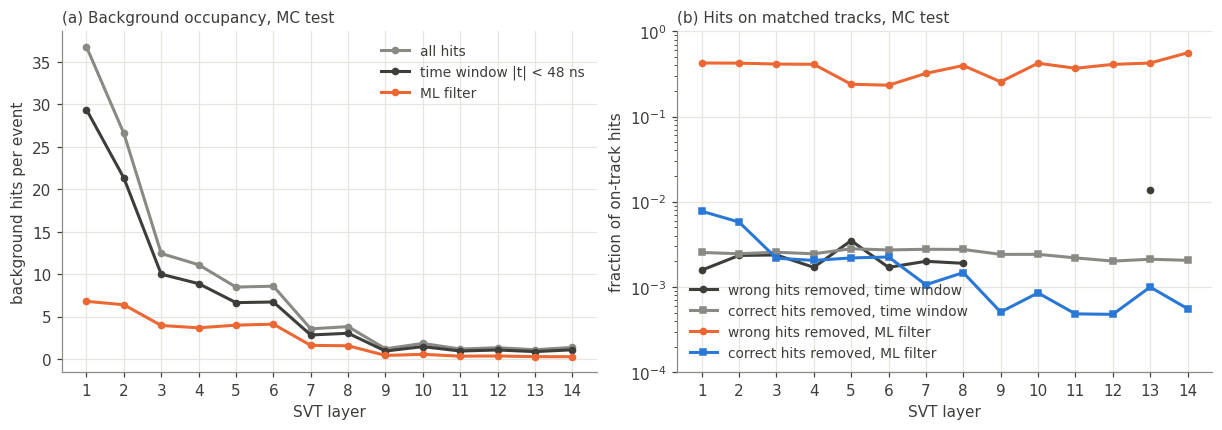

Working point: score >= 0.008351


,found tracks lost,"lost, ECal acceptance",correct on-track hits kept,wrong on-track hits removed,hits of unmatched tracks removed,background hits kept,signal hits kept
ML filter,0.003,0.0004,0.9980,0.3907,0.4979,0.2879,0.9915
time window |t| < 48 ns,0.003,0.0000,0.9975,0.0020,0.1100,0.7976,0.9942


In [8]:
MODEL = "GBDT + context"
sc = scans[MODEL].sort_values("lost")
WP_THR = float(np.interp(MAX_LOST, sc["lost"], sc["threshold"]))
s_mc = scores[MODEL]
keep = s_mc >= WP_THR
L = mc_te["X"][:, FI["layer"]].astype(int)
code_ = mc_te["code"]
# the time window with the same track loss, for comparison
st_ = scan_t.sort_values("lost")
w_eq = float(np.interp(MAX_LOST, st_["lost"], st_["threshold"]))
keep_t = t_abs < w_eq
n_ev = mc_te["n_events"]
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
for k, lab, col in ((np.ones_like(keep), "all hits", C["muted"]), (keep_t, f"time window |t| < {w_eq:.0f} ns", C["ink"]),
                    (keep, "ML filter", C["overlay"])):
    a.plot(st.LAYERS, np.bincount(L[(yt == 0) & k], minlength=15)[1:] / n_ev, "o-", color=col, label=lab, ms=4)
a.set_xticks(st.LAYERS)
st.style(a, "SVT layer", "background hits per event", "(a) Background occupancy, MC test")
for k, lab, cw, cg in ((keep_t, "time window", C["ink"], C["muted"]), (keep, "ML filter", C["overlay"], C["pure"])):
    rem_w = [1 - k[(code_ == 3) & (L == l)].mean() if ((code_ == 3) & (L == l)).sum() > 50 else np.nan for l in st.LAYERS]
    los_g = [1 - k[(code_ == 2) & (L == l)].mean() for l in st.LAYERS]
    rem_w, los_g = [np.where(np.asarray(v) > 0, v, np.nan) for v in (rem_w, los_g)]   # log axis: hide zeros
    b.plot(st.LAYERS, rem_w, "o-", color=cw, label=f"wrong hits removed, {lab}", ms=4)
    b.plot(st.LAYERS, los_g, "s-", color=cg, label=f"correct hits removed, {lab}", ms=4)
b.set_xticks(st.LAYERS); b.set_yscale("log"); b.set_ylim(1e-4, 1)
st.style(b, "SVT layer", "fraction of on-track hits", "(b) Hits on matched tracks, MC test")
plt.show()
wp = hf.track_metrics(mc_te, keep); wpt = hf.track_metrics(mc_te, keep_t)
print(f"Working point: score >= {WP_THR:.4g}")
pd.DataFrame({"ML filter": wp, f"time window |t| < {w_eq:.0f} ns": wpt}).T[
    ["lost", "lost_acc", "good_kept", "wrong_removed", "fake_removed", "bkg_kept", "sig_kept"]].rename(columns={
    "lost": "found tracks lost", "lost_acc": "lost, ECal acceptance", "good_kept": "correct on-track hits kept",
    "wrong_removed": "wrong on-track hits removed", "fake_removed": "hits of unmatched tracks removed",
    "bkg_kept": "background hits kept", "sig_kept": "signal hits kept"}).round(4)

At the working point (score ≥ ~0.008, 0.3 % of found tracks lost, 0.04 % in the ECal acceptance):
- **background:** L1 and L2 drop from 37 and 27 hits per event to about 7 and 6. Overall 71 % of the background
  hits are removed;
- **tracks:** 39 % of the wrong hits on matched tracks and 50 % of the hits on unmatched (background) tracks are
  removed, while 99.8 % of the correct on-track hits are kept. Correct-hit losses are highest in L1–L2 (≈ 0.7 %),
  where the background is densest;
- the time window at the same track loss removes almost no wrong hits.

**Limitation of any pre-tracking filter.** The wrong hits that survive are in time, lie on the road of the track,
and usually have the correct hit within 2 mm. Without the track itself they cannot be distinguished; §7 shows what a
second, post-tracking stage adds.

## 6. Real data

### 6a. Why the filter cannot simply be trained on data

Data have no truth, but two data-driven labels are available:
- **positive-unlabelled (PU):** hits in physics-trigger events (signal + background) against hits in pulser-trigger
  events (background only). The optimal classifier for this task is monotonic in the signal/background likelihood
  ratio, provided the background is the same in both;
- **tag:** hits on golden tracks (signal) against pulser hits (background).

Both are tested here on MC, where the truth is known: `mc_phys` plays the physics triggers, and `mc_puls` (the same
files, other events, MC hits removed) plays the pulser triggers. The signal fraction estimated from the hit counts,
1 − ⟨n⟩_pulser / ⟨n⟩_physics, agrees with the truth, so the emulation is faithful.

signal fraction in 'physics' events: from hit counts 0.1441, truth 0.1406


wrong hits on tracks with PU score above the median of background hits: 0.65


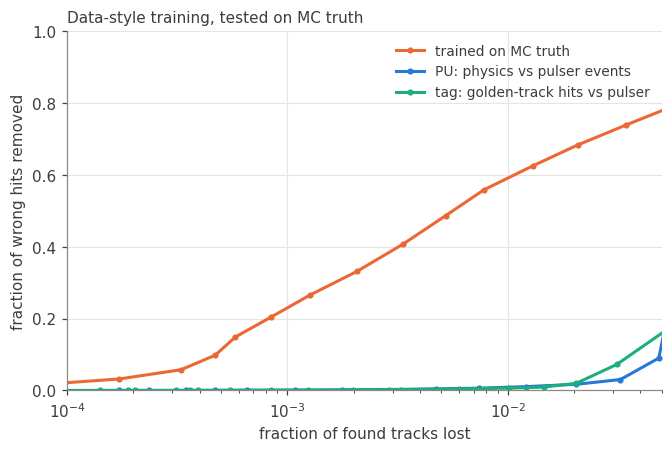

AUC on MC truth: truth-trained 0.9841, PU 0.9095, tag 0.9422


In [9]:
f_est = 1 - (len(mc_puls["X"]) / mc_puls["n_events"]) / (len(mc_phys["X"]) / mc_phys["n_events"])
print(f"signal fraction in 'physics' events: from hit counts {f_est:.4f}, truth {mc_phys['is_mc'].mean():.4f}")
rng = np.random.default_rng(4)
n = 4_000_000
i1 = rng.choice(len(mc_phys["X"]), n, replace=False); i0 = rng.choice(len(mc_puls["X"]), n, replace=False)
pu = gbdt(MONO).fit(np.vstack([mc_phys["X"][i1], mc_puls["X"][i0]]), np.r_[np.ones(n), np.zeros(n)])
g = mc_phys["on_golden"] == 1
i0g = rng.choice(len(mc_puls["X"]), 4 * g.sum(), replace=False)
tag = gbdt(MONO).fit(np.vstack([mc_phys["X"][g], mc_puls["X"][i0g]]), np.r_[np.ones(g.sum()), np.zeros(len(i0g))])
s_pu, s_tag = pu.predict_proba(mc_te["X"])[:, 1], tag.predict_proba(mc_te["X"])[:, 1]
sc_pu, sc_tag = hf.scan(mc_te, s_pu), hf.scan(mc_te, s_tag)

# which hits do the wrong-hit labels call signal?
wr = mc_te["code"] == 3
print(f"wrong hits on tracks with PU score above the median of background hits: {np.mean(s_pu[wr] > np.median(s_pu[yt == 0])):.2f}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(scans[MODEL]["lost"], scans[MODEL]["wrong_removed"], "o-", ms=3, color=C["overlay"], label="trained on MC truth")
ax.plot(sc_pu["lost"], sc_pu["wrong_removed"], "o-", ms=3, color=C["pure"], label="PU: physics vs pulser events")
ax.plot(sc_tag["lost"], sc_tag["wrong_removed"], "o-", ms=3, color=C["third"], label="tag: golden-track hits vs pulser")
ax.set_xscale("log"); ax.set_xlim(1e-4, 0.05); ax.set_ylim(0, 1)
st.style(ax, "fraction of found tracks lost", "fraction of wrong hits removed", "Data-style training, tested on MC truth")
plt.show()
print(f"AUC on MC truth: truth-trained {roc_auc_score(yt, s_mc):.4f}, PU {roc_auc_score(yt, s_pu):.4f}, tag {roc_auc_score(yt, s_tag):.4f}")

- **Both data-style labels fail exactly on the wrong hits.** A wrong hit is a background hit that happens to sit
  next to a physics track, so it exists only in physics events and next to tagged tracks. PU and tag labels
  therefore teach the model that such hits are *signal*: 65 % of the wrong hits get a PU score above the median of
  the background.
- On MC truth, PU reaches AUC 0.91 and tag 0.94 (truth-trained: 0.984). At equal track loss they remove almost no
  wrong hits.
- **Conclusion:** the decision boundary must come from MC truth. Real data are used to correct the MC inputs
  (6c) and to set the working point (6e).

### 6b. How different are data and MC?

**The right MC reference.** In the overlay MC the background hits *are* real pulser data, and the signal hits sit
in that real background. Two different questions follow:
- **Is the hit response simulated correctly?** Hits on golden tracks in run 14229 against golden-track hits in
  the **pure MC**, where every hit is simulated. Only response features are used, defined by the hit and its own
  track: sensor (layer, half, stereo, side), time, charge, cluster size, partner-sensor match (`pair_dt`,
  `pair_dy`) and road timing (`road_adt`, `road_at`). Occupancy features (`nsame`, `ncomp`, `noot_half`, road
  counts) are excluded: the pure MC has no background, so they would only measure its absence. Kinematic features
  (|y|, tan λ) are excluded too, since the data golden tracks also contain FEE and WAB.
- **Is the background the same?** Run-14229 pulser events against the overlaid pulser events. Both are real data,
  so this measures the run-to-run difference (beam current, occupancy, timing) between the run used for the
  overlay (run-14272 headers) and run 14229, not the simulation.

For reference, the golden-track hits of the overlay MC are shown as well. They differ from the pure MC only through
the real background around them (pile-up in the same strips, wrong hits picked up by the tracks).

A classifier trained to separate two samples measures their difference: AUC = 0.5 means no difference.

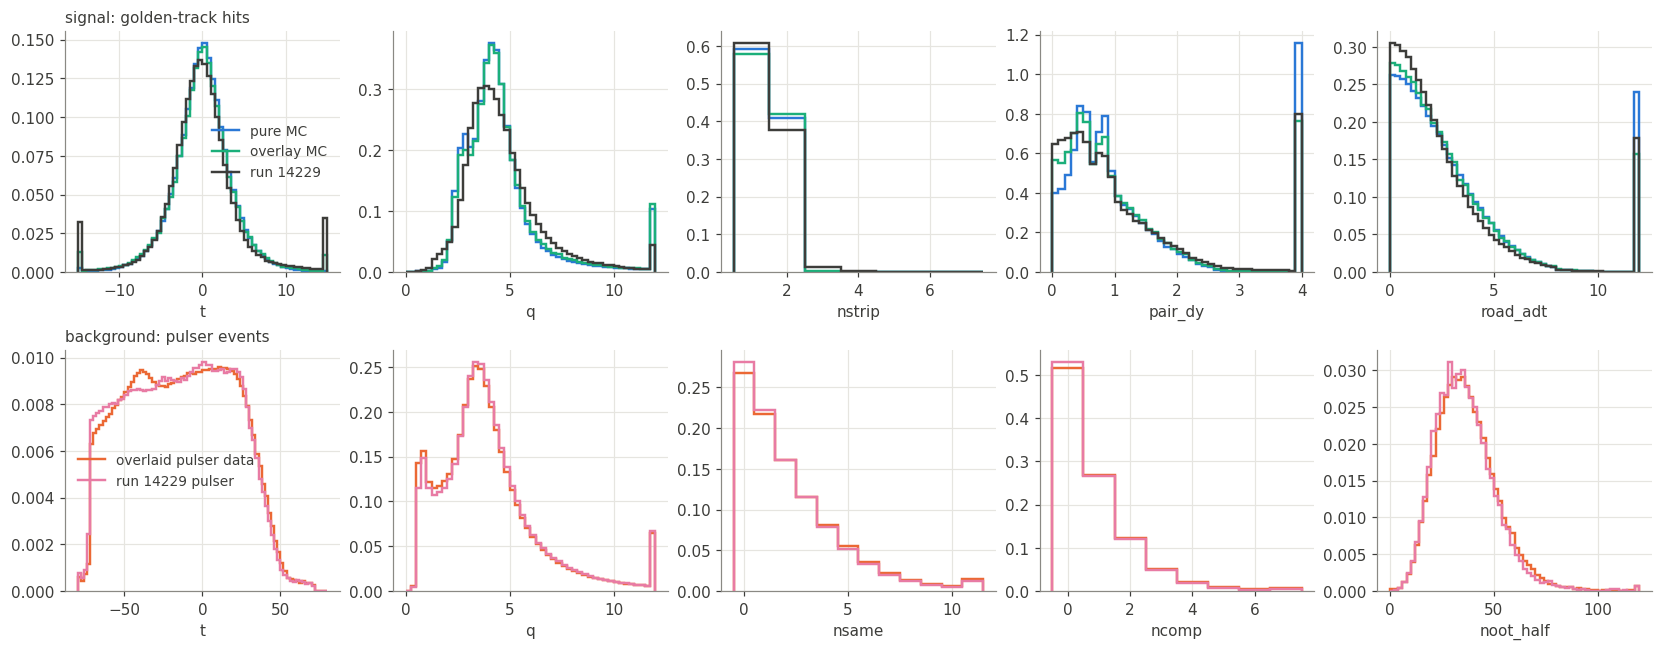

,separation AUC
signal response: run 14229 vs pure MC,0.812
signal response: run 14229 vs overlay MC,0.757
signal response: overlay vs pure MC (effect of the real background),0.605
background: run 14229 pulser vs overlaid pulser data (all features),0.681


In [10]:
SIM = [FI[f] for f in ("layer", "top", "stereo", "side", "t", "q", "nstrip", "pair_dt", "pair_dy", "road_adt", "road_at")]
BARE = [FI[f] for f in ("layer", "top", "stereo", "side", "t", "q", "nstrip")]   # the hit alone: no other hit involved
RESPONSE = [FI[f] for f in ("layer", "top", "stereo", "side", "t", "q", "nstrip", "pair_dt", "pair_dy", "road_adt",
                              "road_at", "ncomp", "nsame")]          # SIM + local occupancy (previous choice, overlay reference)
d_puls_even = d_puls["event_number"] % 2 == 0      # split pulser events: even for reweighting, odd for evaluation
mc_gold = mc_phys["X"][mc_phys["on_golden"] == 1]  # overlay MC
pure_gold = mc_pure["X"][mc_pure["on_golden"] == 1]
G = {"pure MC": pure_gold, "overlay MC": mc_gold, "run 14229": d_gold_a}
GC = {"pure MC": C["pure"], "overlay MC": C["third"], "run 14229": C["ink"]}
B = {"overlaid pulser data": mc_puls["X"], "run 14229 pulser": d_puls["X"][d_puls_even]}
BC = {"overlaid pulser data": C["overlay"], "run 14229 pulser": "#e87ba4"}
bins6 = {"t": np.linspace(-15, 15, 61), "q": np.linspace(0, 12, 49), "nstrip": np.arange(0.5, 8), "pair_dy": np.linspace(0, 4, 41),
         "road_adt": np.linspace(0, 12, 49), "tb": np.linspace(-80, 80, 81), "nsame": np.arange(-0.5, 12),
         "noot_half": np.linspace(0, 120, 61), "ncomp": np.arange(-0.5, 8)}
fig, axes = plt.subplots(2, 5, figsize=(15, 5.8))
for ax, f in zip(axes[0], ("t", "q", "nstrip", "pair_dy", "road_adt")):
    for name, X_ in G.items():
        h, _ = np.histogram(np.clip(X_[:, FI[f]], bins6[f][0], bins6[f][-1] - 1e-9), bins=bins6[f], density=True)
        ax.stairs(h, bins6[f], color=GC[name], lw=1.6, label=name)
    st.style(ax, f, None, "signal: golden-track hits" if f == "t" else None, legend=(f == "t"))
for ax, f in zip(axes[1], ("t", "q", "nsame", "ncomp", "noot_half")):
    b_ = bins6["tb" if f == "t" else f]
    for name, X_ in B.items():
        h, _ = np.histogram(np.clip(X_[:, FI[f]], b_[0], b_[-1] - 1e-9), bins=b_, density=True)
        ax.stairs(h, b_, color=BC[name], lw=1.6, label=name)
    st.style(ax, f, None, "background: pulser events" if f == "t" else None, legend=(f == "t"))
plt.show()

def sep_auc(A, B_, cols, n_max=1_000_000):
    """AUC of a classifier separating A from B_ (features cols), on a held-out half."""
    nn = min(len(A), len(B_), n_max)
    ia, ib = rng.choice(len(A), nn, replace=False), rng.choice(len(B_), nn, replace=False)
    half = nn // 2
    clf = HGB(max_iter=150, max_leaf_nodes=31, early_stopping=True, random_state=1).fit(
        np.vstack([A[ia[:half]][:, cols], B_[ib[:half]][:, cols]]), np.r_[np.ones(half), np.zeros(half)])
    pa = clf.predict_proba(np.vstack([A[ia[half:]][:, cols], B_[ib[half:]][:, cols]]))[:, 1]
    return roc_auc_score(np.r_[np.ones(nn - half), np.zeros(nn - half)], pa)
auc_dm = {"signal response: run 14229 vs pure MC": sep_auc(d_gold_a, pure_gold, SIM),
          "signal response: run 14229 vs overlay MC": sep_auc(d_gold_a, mc_gold, SIM),
          "signal response: overlay vs pure MC (effect of the real background)": sep_auc(mc_gold, pure_gold, SIM),
          "background: run 14229 pulser vs overlaid pulser data (all features)": sep_auc(B["run 14229 pulser"], B["overlaid pulser data"], ALL)}
pd.Series(auc_dm, name="separation AUC").round(3).to_frame()

In [11]:
# Where the response differs: per layer group, for hits on golden tracks
def response_table(groups=((1, 2), (3, 4), (5, 8), (9, 14))):
    rows = []
    for name, X_ in G.items():
        Lg = X_[:, FI["layer"]]
        for lo, hi in groups:
            m = (Lg >= lo) & (Lg <= hi)
            t_ = X_[m, FI["t"]]
            rows.append({"layers": f"L{lo}-L{hi}", "sample": name,
                         "time: median [ns]": np.median(t_), "time: σ68 [ns]": np.diff(np.percentile(t_, [16, 84]))[0] / 2,
                         "charge: median": np.median(X_[m, FI["q"]]), "charge: 90 %": np.percentile(X_[m, FI["q"]], 90),
                         "strips: mean": X_[m, FI["nstrip"]].mean(),
                         "partner within 4 mm, 8 ns": (X_[m, FI["pair_dy"]] < 4).mean(),
                         "|t - road time|: median [ns]": np.median(X_[m, FI["road_adt"]])})
    return pd.DataFrame(rows).set_index(["layers", "sample"])
response_table().round(3)

,,time: median [ns],time: σ68 [ns],charge: median,charge: 90 %,strips: mean,"partner within 4 mm, 8 ns",|t - road time|: median [ns]
layers,sample,,,,,,,
L1-L2,pure MC,0.043,4.224,2.955,4.530,1.094,0.759,3.092
L3-L4,pure MC,0.030,4.226,2.953,4.493,1.095,0.815,2.861
L5-L8,pure MC,0.079,2.701,4.478,6.883,1.544,0.920,1.885
L9-L14,pure MC,0.064,2.528,4.524,7.008,1.523,0.922,1.811
L1-L2,overlay MC,-0.013,5.011,3.049,5.956,1.140,0.911,2.632
L3-L4,overlay MC,0.031,4.341,2.993,4.916,1.117,0.899,2.570
L5-L8,overlay MC,0.044,2.817,4.505,7.279,1.557,0.937,1.845
L9-L14,overlay MC,0.060,2.554,4.533,7.109,1.535,0.927,1.781
L1-L2,run 14229,-0.278,5.351,3.466,6.406,1.157,0.921,2.434


In [12]:
# Single-feature separation |AUC - 0.5| for each response feature (which features drive the difference)
def one_feature_auc(A, B_, f, n=400_000):
    a = A[rng.choice(len(A), min(n, len(A)), replace=False), FI[f]]
    b = B_[rng.choice(len(B_), min(n, len(B_)), replace=False), FI[f]]
    return abs(roc_auc_score(np.r_[np.ones(len(a)), np.zeros(len(b))], np.r_[a, b]) - 0.5)
sim_names = [hf.FEATURES[i] for i in SIM if hf.FEATURES[i] not in ("layer", "top", "stereo", "side")]
pd.DataFrame({"run 14229 vs pure MC": [one_feature_auc(d_gold_a, pure_gold, f) for f in sim_names],
              "run 14229 vs overlay MC": [one_feature_auc(d_gold_a, mc_gold, f) for f in sim_names],
              "overlay vs pure MC": [one_feature_auc(mc_gold, pure_gold, f) for f in sim_names]},
             index=pd.Index(sim_names, name="feature")).round(3)

,run 14229 vs pure MC,run 14229 vs overlay MC,overlay vs pure MC
feature,,,
t,0.020,0.017,0.002
q,0.029,0.015,0.014
nstrip,0.005,0.013,0.007
pair_dt,0.072,0.031,0.043
pair_dy,0.034,0.002,0.032
road_adt,0.039,0.024,0.016
road_at,0.100,0.081,0.017


**Simulation of the hit response (run 14229 vs pure MC).** The two are clearly separable: classifier AUC
0.81, against 0.76 for data vs overlay MC. The table locates the differences:
- **Time resolution is mis-modelled layer by layer**, even though the global time distributions agree. Width σ68
  of hits on golden tracks, data vs pure MC:

  | layers | data | pure MC |
  |---|---|---|
  | L1–L2 | 5.4 ns | 4.2 ns |
  | L3–L4 | 2.9 ns | 4.2 ns |
  | L5–L8 | 3.7 ns | 2.7 ns |
  | L9–L14 | 2.6 ns | 2.5 ns |

  The MC time smearing (`RawHitTimeSmearer`, file `timeSmearing-2nsL4L7-4nsL1L3.txt`) is too large in L3–L4 and
  too small in L5–L8. The data also have residual time offsets of −0.5 to +0.25 ns between layer groups, while the
  MC has none. This is why the road time (`road_at`) is the most different single feature.
- **Charge is higher in data in L1–L4** (median +17 % to +23 %) and agrees within 2–4 % in L5–L14.
- **Cluster size:** larger in data in L3–L4 (1.21 vs 1.10 strips) and slightly smaller in L5–L8 (1.47 vs 1.54).

**What the real background changes (overlay vs pure MC, AUC 0.61).** Several "response" features of a simulated
hit depend on the background around it:
- in L1–L2 the 90 % charge quantile goes from 4.5 to 6.0 (pile-up);
- the fraction of hits with a partner within 4 mm and 8 ns goes from 0.76 to 0.91 (random partners; data: 0.92);
- the time tail extends to −75 ns (§3).

Data share these effects. A pure-MC reference therefore measures the simulation *plus* the background. Used for
reweighting the overlay training hits, which already contain the background, it would apply the background effect
a second time. Hence the two roles:
- the **pure MC** is the reference for judging the simulation (the table above: input for MC tuning);
- the **overlay MC** is the reference for correcting the training sample.

**Background (run 14229 vs overlaid pulser data, AUC 0.68).** This is data against data. The distributions agree
except for a bump near −40 ns in run 14229 and slightly different occupancy: these are run-to-run differences (the
overlay used pulser data with run-14272 headers), not simulation.

### 6c. Fine-tuning on data: pre-train on MC truth, reweight to the data

The decision boundary must come from MC truth (6a), but the MC inputs can be corrected with real data. Each MC
training hit gets a weight w(x) = p_data(x) / p_MC(x), estimated by a classifier on the control samples of 6b:
- MC **signal** hits (the simulated part) are reweighted with a response classifier, run 14229 against an MC
  reference. Kinematic features are never used, so the physics mix (FEE and WAB in the data golden tracks, tritrig
  in the MC) is not imported. Two choices of reference are compared:
  - **pure-MC reference**: run 14229 vs pure MC, on the *bare* hit response (sensor, time, charge, cluster size).
    Features that involve other hits (partner, road) are left out, because 6b shows the real background changes
    them: a pure-MC reference would credit the background's effect to the simulation and apply it twice to the
    overlay training hits. Even so, some pile-up charge in L1–L2 remains in this correction;
  - **overlay reference**: run 14229 vs overlay MC golden-track hits, with the partner, road and occupancy
    features included. The overlay already contains the real background, so the ratio isolates the simulation
    and run-to-run differences. This was the first version of this study;
- MC **background** hits are reweighted with the pulser classifier, run 14229 vs overlaid pulser data (all
  features). Both are real data, so this corrects run-to-run differences only.

The model is then retrained on the weighted MC: the data define the input distributions, and MC truth defines which
hits are wrong. Which reference works better is decided on real data, at equal golden-track loss (6e).

In [13]:
def reweighted_model(sig_target, sig_source, sig_cols):
    w = np.ones(len(y))
    w_sig, _ = hf.reweight(sig_target, sig_source, mc_tr["X"][y == 1], features=sig_cols)
    w[y == 1], w[y == 0] = w_sig, w_bkg
    return gbdt(MONO).fit(X, y, sample_weight=w), w_sig

w_bkg, clf_bkg = hf.reweight(B["run 14229 pulser"], B["overlaid pulser data"], mc_tr["X"][y == 0])
t0 = time.time()
final_pu, w_sig = reweighted_model(d_gold_a, pure_gold, BARE)
final_ov, w_sig_ov = reweighted_model(d_gold_a, mc_gold, RESPONSE)
print(f"retrained 2 models in {time.time() - t0:.0f} s; weights 5-95 %: signal (pure ref.) {np.percentile(w_sig, [5, 95]).round(2)}, "
      f"signal (overlay ref.) {np.percentile(w_sig_ov, [5, 95]).round(2)}, background {np.percentile(w_bkg, [5, 95]).round(2)}")

RW = ("reweighted, pure-MC reference", "reweighted, overlay reference")
MODELS = {"MC-only model": bench[MODEL][0], RW[0]: final_pu, RW[1]: final_ov}
MCOL = {"MC-only model": C["pure"], RW[0]: C["third"], RW[1]: C["overlay"]}
THR_MC_ = {"MC-only model": WP_THR}
mc_rows = {"MC-only model": wp}
S_TE = {"MC-only model": s_mc}
for name in RW:
    S_TE[name] = s_ = MODELS[name].predict_proba(mc_te["X"])[:, 1]
    sc_ = hf.scan(mc_te, s_).sort_values("lost")
    THR_MC_[name] = float(np.interp(MAX_LOST, sc_["lost"], sc_["threshold"]))
    mc_rows[name] = hf.track_metrics(mc_te, s_ >= THR_MC_[name])
print("MC truth, each model at its own MC working point (0.3 % of found tracks lost):")
pd.DataFrame(mc_rows).T[["lost", "lost_acc", "good_kept", "wrong_removed", "bkg_kept"]].assign(threshold=pd.Series(THR_MC_)).round(4)

retrained 2 models in 70 s; weights 5-95 %: signal (pure ref.) [0.39 0.66], signal (overlay ref.) [0.11 3.39], background [0.22 1.99]


MC truth, each model at its own MC working point (0.3 % of found tracks lost):


,lost,lost_acc,good_kept,wrong_removed,bkg_kept,threshold
MC-only model,0.003,0.0004,0.9980,0.3907,0.2879,0.0084
"reweighted, pure-MC reference",0.003,0.0004,0.9988,0.0817,0.6460,0.0139
"reweighted, overlay reference",0.003,0.0004,0.9986,0.2903,0.4916,0.0091


### 6d. Validation on real data

Without truth, the filter is checked on data with the tags:
- **pulser-event hits kept** (pure background; odd events, not used for the reweighting);
- **golden-track hits kept** and **golden tracks lost** (no longer findable with the kept hits; file 0, not used
  for the reweighting);
- **hits removed per physics event**, by layer.

The same quantities are computed on the MC test sample for comparison. Each model is used at its MC working point
here; 6e compares them at equal safety on data.

In [14]:
d_puls_odd = ~d_puls_even
def data_eval(model, thr):
    s_ph, s_pu_ = model.predict_proba(d_phys["X"])[:, 1], model.predict_proba(d_puls["X"][d_puls_odd])[:, 1]
    s_te = model.predict_proba(mc_te["X"])[:, 1]
    gm_d, gm_m = hf.golden_metrics(d_phys, s_ph >= thr), hf.golden_metrics(mc_te, s_te >= thr)
    return {"data: pulser hits kept": (s_pu_ >= thr).mean(), "MC: background hits kept": (s_te[yt == 0] >= thr).mean(),
            "data: golden hits kept": gm_d["golden_hits_kept"], "MC: golden hits kept": gm_m["golden_hits_kept"],
            "data: golden tracks lost": gm_d["golden_tracks_lost"], "MC: golden tracks lost": gm_m["golden_tracks_lost"],
            "data: hits kept / physics event": (s_ph >= thr).sum() / d_phys["n_events"],
            "data: hits / physics event": len(s_ph) / d_phys["n_events"],
            "MC: hits kept / event": (s_te >= thr).sum() / mc_te["n_events"]}, s_ph
ev, s_ph = {}, {}
for name, m_ in MODELS.items():
    ev[name], s_ph[name] = data_eval(m_, THR_MC_[name])
print(f"golden tracks: data {hf.golden_metrics(d_phys, np.ones(len(d_phys['X']), bool))['n_golden_tracks']}, "
      f"MC {hf.golden_metrics(mc_te, np.ones(len(mc_te['X']), bool))['n_golden_tracks']}")
pd.DataFrame(ev).round(4)

golden tracks: data 19368, MC 11606


,MC-only model,"reweighted, pure-MC reference","reweighted, overlay reference"
data: pulser hits kept,0.3227,0.6562,0.5079
MC: background hits kept,0.2879,0.6460,0.4916
data: golden hits kept,0.9777,0.9929,0.9873
MC: golden hits kept,0.9909,0.9975,0.9929
data: golden tracks lost,0.0154,0.0031,0.0039
MC: golden tracks lost,0.0006,0.0000,0.0001
data: hits kept / physics event,54.1134,93.9768,76.1946
data: hits / physics event,134.8724,134.8724,134.8724
MC: hits kept / event,52.1838,94.9665,76.5716


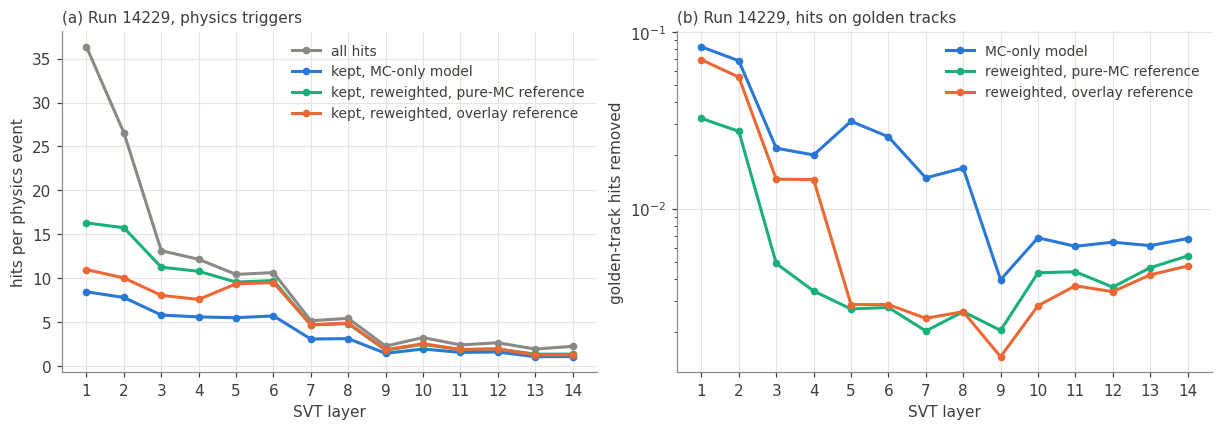

In [15]:
Ld = d_phys["X"][:, FI["layer"]].astype(int)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
nd = d_phys["n_events"]
a.plot(st.LAYERS, np.bincount(Ld, minlength=15)[1:] / nd, "o-", color=C["muted"], label="all hits", ms=4)
gsel = d_phys["golden_trk"] >= 0
for name in MODELS:
    keep_d = s_ph[name] >= THR_MC_[name]
    a.plot(st.LAYERS, np.bincount(Ld[keep_d], minlength=15)[1:] / nd, "o-", color=MCOL[name], label=f"kept, {name}", ms=4)
    b.plot(st.LAYERS, [1 - keep_d[gsel & (Ld == l)].mean() for l in st.LAYERS], "o-", color=MCOL[name], label=name, ms=4)
a.set_xticks(st.LAYERS)
st.style(a, "SVT layer", "hits per physics event", "(a) Run 14229, physics triggers")
b.set_xticks(st.LAYERS); b.set_yscale("log")
st.style(b, "SVT layer", "golden-track hits removed", "(b) Run 14229, hits on golden tracks")
plt.show()

- **The MC-only model is not safe on data.** It loses 1.5 % of the golden tracks in run 14229, against 0.06 % in
  MC, and removes 2–3 % of the golden-track hits in L5–L8, where MC predicts ≈ 0.3 %. The data/MC differences of 6b
  (mainly timing) push real signal hits into regions the MC-only model treats as background.
- **Both reweighted models are about 4× safer on data** (0.31 % and 0.39 % of golden tracks lost at their MC
  working points). The pure-MC-reference model is safe mostly because it is much less aggressive: it keeps 66 % of
  the pulser hits and, on MC, removes only 8 % of the wrong hits. Its weights are concentrated on few hits (5–95 %
  range 0.39–0.66, the rest clipped at high values). The data-vs-pure-MC classifier separates too easily, partly
  because of the background effects of 6b.
- For all three models the rejection of pulser hits on data matches the MC expectation (32/29 %, 66/65 %, 51/49 %
  kept), so the background is well modelled. The differences are on the signal side.
- The fixed-threshold comparison is not fair between the models; 6e compares them at equal safety on data.

### 6e. Working point calibrated on data

A threshold chosen on MC does not give the same track loss on data (6d). The final threshold is therefore set
**on data**: scan the threshold, and for each value measure on run 14229 the fraction of golden tracks that would
become unfindable and the fraction of pulser hits removed. Compared at equal safety on data, the model that removes
the most pulser hits is exported, with the threshold at which `MAX_LOST` (0.3 %) of the golden tracks are lost.
Golden tracks carry some wrong hits themselves, so this loss is an upper limit.

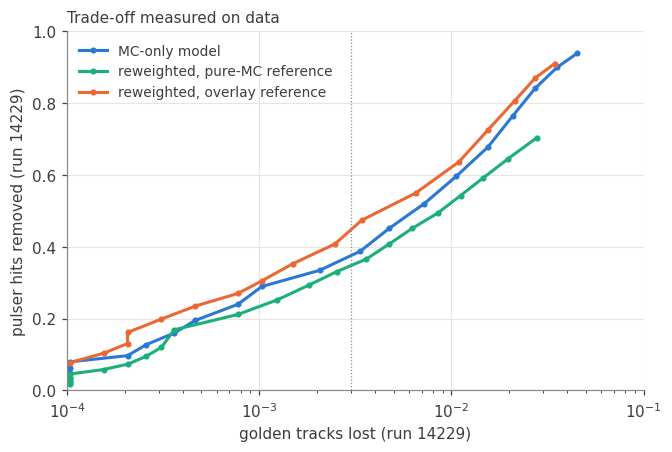

Best on data at 0.3% golden-track loss: reweighted, overlay reference; data threshold 0.007241, MC threshold 0.009064


,threshold,golden_hits_kept,pulser_removed,hits_kept_per_event
MC-only model,0.0018,0.9942,0.3732,90.7760
"reweighted, pure-MC reference",0.0140,0.9927,0.3462,93.7030
"reweighted, overlay reference",0.0072,0.9896,0.4450,81.8668


In [16]:
def data_scan(model, quantiles=np.r_[0.0, np.geomspace(1e-4, 0.08, 22)]):
    s_ph_ = model.predict_proba(d_phys["X"])[:, 1]
    s_pq = model.predict_proba(d_puls["X"][d_puls_odd])[:, 1]
    thr = np.quantile(s_ph_[d_phys["on_golden"] == 1], quantiles)
    rows = []
    for t_ in thr:
        g_ = hf.golden_metrics(d_phys, s_ph_ >= t_)
        rows.append(dict(threshold=t_, golden_tracks_lost=g_["golden_tracks_lost"], golden_hits_kept=g_["golden_hits_kept"],
                         pulser_removed=1 - (s_pq >= t_).mean(), hits_kept_per_event=(s_ph_ >= t_).sum() / d_phys["n_events"]))
    return pd.DataFrame(rows).sort_values("golden_tracks_lost")
dscan = {name: data_scan(m_) for name, m_ in MODELS.items()}
fig, ax = plt.subplots(figsize=(6, 4))
for name, ds in dscan.items():
    ax.plot(ds["golden_tracks_lost"], ds["pulser_removed"], "o-", ms=3, color=MCOL[name], label=name)
ax.axvline(MAX_LOST, color=C["muted"], lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_xlim(1e-4, 0.1); ax.set_ylim(0, 1)
st.style(ax, "golden tracks lost (run 14229)", "pulser hits removed (run 14229)", "Trade-off measured on data")
plt.show()
wp_data = {name: {c: float(np.interp(MAX_LOST, ds["golden_tracks_lost"], ds[c])) for c in ds.columns if c != "golden_tracks_lost"}
           for name, ds in dscan.items()}
BEST = max(wp_data, key=lambda k: wp_data[k]["pulser_removed"])
EXPORT_MODEL = final = MODELS[BEST]
s_final = S_TE[BEST]
THR_DATA, THR_MC = wp_data[BEST]["threshold"], THR_MC_[BEST]
print(f"Best on data at {MAX_LOST:.1%} golden-track loss: {BEST}; data threshold {THR_DATA:.4g}, MC threshold {THR_MC:.4g}")
pd.DataFrame(wp_data).T.round(4)

- **At equal golden-track loss on data, the overlay-reference model removes the most background over the whole
  range.** At 0.3 % lost it removes 44.5 % of the pulser hits; the MC-only model removes 37 % and the
  pure-MC-reference model 35 %. Correcting the simulation alone (pure-MC reference) does not help, because part of
  the data/MC difference of the signal hits is caused by the real background, which the overlay already contains.
- **Exported: the overlay-reference model.** It is the same model as in the first version of this study, so the
  hps-java reconstruction test applies unchanged. Threshold for run 14229: 0.0072. It keeps 82 of the 135 hits per
  physics event and 99.0 % of the golden-track hits. For the overlay MC the threshold is 0.0091 (at 0.3 % lost found
  tracks). Both are stored in the model file; the default is the data one.
- The data working point is looser than the MC one: real data need a more conservative cut to be equally safe.
- **Better MC would help directly.** The per-layer time resolution and offsets found in 6b are the largest data/MC
  differences. Retuning the MC time smearing per layer would make the MC working point transferable to data.

## 7. Beyond pre-filtering: hits on tracks (stage 2)

Section 5 shows the limit of any pre-tracking filter. The wrong hits that remain are in time and on the road of the
track, and the correct hits that are lost have badly measured times and no road. Once the track exists, its time
(±1.7 ns) and its hits give the missing context. A second classifier is trained here for the (track, hit) pairs of
matched tracks (correct vs wrong), with inputs: hit time − track time, track hit count and χ²/ndf, number of tracks
sharing the hit, the stage-1 score, and the hit features.

In [17]:
def pairs(d, s1):
    T = d["trk"]; r = T["hit_row"]
    Z = np.column_stack([T["dt"], np.abs(T["dt"]), T["trk_nhits"], T["trk_chi2ndf"], T["nshare"], s1[r], d["X"][r]])
    return Z, T
s1_tr = final.predict_proba(mc_tr["X"])[:, 1]
Ztr, Ttr = pairs(mc_tr, s1_tr); Zte, Tte = pairs(mc_te, s_final)
mtr, mte = Ttr["label"] >= 2, Tte["label"] >= 2
y2, y2t = (Ttr["label"][mtr] == 2).astype(int), (Tte["label"][mte] == 2).astype(int)
stage2 = HGB(max_iter=300, max_leaf_nodes=31, min_samples_leaf=100, l2_regularization=1.0, early_stopping=True,
             random_state=1).fit(Ztr[mtr], y2)
p2 = stage2.predict_proba(Zte[mte])[:, 1]
key = Tte["event"][mte] * 100 + Tte["track"][mte].astype(int)
_, inv = np.unique(key, return_inverse=True)
n_h, n_w = np.bincount(inv), np.bincount(inv, weights=1 - y2t)
def stage2_row(k):
    kw, kn = np.bincount(inv, weights=k * (1 - y2t)), np.bincount(inv, weights=k)
    kg = np.bincount(inv, weights=k * y2t)
    return {"correct hits removed": 1 - k[y2t == 1].mean(), "wrong hits removed": 1 - k[y2t == 0].mean(),
            "clean tracks": np.mean(kw == 0), "tracks losing a correct hit": np.mean(kg < n_h - n_w),
            "tracks left with < 6 hits": np.mean(kn < 6)}
rows = {"no stage 2": stage2_row(np.ones(len(y2t), bool))}
for w_ in (8, 10, 15):
    rows[f"|hit − track time| < {w_} ns"] = stage2_row(np.abs(Zte[mte, 0]) < w_)
for q in (0.002, 0.005, 0.01):
    rows[f"stage-2 BDT, {q:.1%} correct hits lost"] = stage2_row(p2 >= np.quantile(p2[y2t == 1], q))
print(f"(track, hit) pairs on matched tracks in the test sample: {mte.sum()}, wrong: {1 - y2t.mean():.3f}; "
      f"stage-2 AUC {roc_auc_score(y2t, p2):.4f}, |dt| alone {roc_auc_score(y2t, -Zte[mte, 1]):.4f}")
pd.DataFrame(rows).T.round(4)

(track, hit) pairs on matched tracks in the test sample: 743215, wrong: 0.061; stage-2 AUC 0.9849, |dt| alone 0.8705


,correct hits removed,wrong hits removed,clean tracks,tracks losing a correct hit,tracks left with < 6 hits
no stage 2,0.0000,0.0000,0.6177,0.0000,0.0002
|hit − track time| < 8 ns,0.0687,0.6845,0.8392,0.4286,0.0609
|hit − track time| < 10 ns,0.0351,0.6101,0.8107,0.2359,0.0387
|hit − track time| < 15 ns,0.0085,0.4359,0.7524,0.0613,0.0125
"stage-2 BDT, 0.2% correct hits lost",0.0020,0.5740,0.7933,0.0205,0.0163
"stage-2 BDT, 0.5% correct hits lost",0.0050,0.6912,0.8390,0.0498,0.0255
"stage-2 BDT, 1.0% correct hits lost",0.0100,0.7684,0.8736,0.0951,0.0348


- **Once the track exists, wrong hits are much easier to recognise.** Stage 2 reaches AUC 0.985 on (track, hit)
  pairs. Losing only 0.2 % of the correct hits, it removes 57 % of the remaining wrong hits and raises the fraction
  of clean tracks from 62 % to 79 %. At 0.5 %: 69 % removed, 84 % clean.
- A plain |hit − track time| cut is much worse: it needs to lose 3.5 % of correct hits to remove 61 %.
- **Implementation needs a refit.** hps-java can remove a hit and refit only inside the KF (`KalTrack.removeHit` /
  `fit`); the LCIO tracks written out cannot be refitted by a plug-in driver. Options:
  - a hook in `KalmanPatRecHPS` (next to `removeBadHits`) that calls the stage-2 model;
  - a post-KF driver that refits the cleaned hit lists with the GBL refitter.

  Both go beyond a steering-file change, so stage 2 is a recommendation, not part of the driver.

## 8. Export, Java parity test and steering

The model chosen in 6e is written to `models/svt_hitfilter_v1.txt` (plain text, read by `TreeEnsembleModel.java`)
together with its working point and metadata; the MC-only model to `models/svt_hitfilter_mc_v1.txt`. Then:
1. the exported file is re-read in Python and compared with scikit-learn;
2. the raw hit inputs of 300 test events, with the Python features and scores, are written to
   `models/parity_overlay.csv`, and the Java code (`hps-java/`) recomputes features and scores from the raw inputs.

In [18]:
meta = {"t0": hf.T0["run14229"], "t0_overlay_mc": hf.T0["overlay"], "t0_run14229": hf.T0["run14229"],
        "targetZ": hf.TARGET_Z, "max_lost_found_tracks": MAX_LOST,
        "trained_on": f"tritrig_pulser_beamspot_run14272 overlay MC files 0-39; {BEST} (run 14229)",
        "created": time.strftime("%Y-%m-%d")}
meta.update({"model": BEST, "threshold_run14229": THR_DATA, "threshold_overlay_mc": THR_MC})
path = hf.export_model([EXPORT_MODEL], f"{OUT}/svt_hitfilter_v1.txt", ["mc" if BEST == "MC-only model" else "mc_reweighted_to_run14229"],
                       THR_DATA, meta)
hf.export_model([bench[MODEL][0]], f"{OUT}/svt_hitfilter_mc_v1.txt", ["mc"], WP_THR, {**meta, "model": "MC-only model",
                "threshold_overlay_mc": WP_THR, "trained_on": "overlay MC files 0-39"})
exp = hf.load_model(path)
chk = mc_te["X"][:200_000]
diff = np.abs(hf.predict_exported(exp, chk) - EXPORT_MODEL.predict_proba(chk)[:, 1]).max()

# MC test steering: production overlay-MC recon steering + the filter at the MC working point
base = "/net/home/erbaz/hps-java/steering-files/src/main/resources/org/hps/steering/recon/PhysicsRun2021MCRecon_KF_WithSpacing_pass5_physics_HitSmear_HitKill_14272.lcsim"
xml = open(base).read()
xml = xml.replace('        <driver name="KalmanPatRecDriver"/>', '        <driver name="SvtHitFilter"/>            <!-- ML SVT hit filter (SVT/Hit_Filtering) -->\n        <driver name="KalmanPatRecDriver"/>', 1)
block = "\n".join(["    <drivers>",
                   '        <driver name="SvtHitFilter" type="org.hps.recon.tracking.hitfilter.SvtHitFilterDriver">',
                   f"            <modelFile>{os.path.abspath(path)}</modelFile>",
                   f"            <timeOffset>{hf.T0['overlay']}</timeOffset>     <!-- signal hit time of the overlay MC [ns] -->",
                   f"            <threshold>{THR_MC:.6g}</threshold>          <!-- MC working point; the file default is the run-14229 one -->",
                   "        </driver>", ""])
xml = xml.replace("    <drivers>\n", block, 1)
steer = "hps-java/steering/PhysicsRun2021MCRecon_KF_WithSpacing_pass5_physics_HitSmear_HitKill_14272_SvtHitFilter.lcsim"
open(steer, "w").write(xml)
print("wrote", steer)
print(f"{path}: {os.path.getsize(path) / 1e6:.1f} MB, {len(exp['stages'][0]['trees'])} trees; "
      f"max |exported - sklearn| = {diff:.2e}")

# parity file: raw inputs + Python features + score for 300 events of one test file
df = hf.mc_frame("overlay", TEST[:1])
for c in ("layer", "module", "time", "y", "z", "edep"):
    df = df.Define(f"raw_{c}", f"svt_hit_{c}[hf_use]")
df = df.Define("raw_nstrip", "svt::hf::n_strips(svt_hit_strip)[hf_use]")
a = df.Filter("rdfentry_ < 300").AsNumpy(["rdfentry_", "hf_feat"] + [f"raw_{c}" for c in ("layer", "module", "time", "y", "z", "edep", "nstrip")])
rows = []
for k in range(len(a["rdfentry_"])):
    feat = np.asarray(a["hf_feat"][k], np.float32).reshape(-1, len(hf.FEATURES))
    sc_ = hf.predict_exported(exp, feat)
    for j in range(len(feat)):
        rows.append([a["rdfentry_"][k]] + [a[f"raw_{c}"][k][j] for c in ("layer", "module", "time", "y", "z", "edep", "nstrip")]
                    + [hf.T0["overlay"], hf.TARGET_Z] + list(feat[j]) + [sc_[j]])
cols = ["event", "layer", "module", "time", "y", "z", "edep", "nstrip", "t0", "zT"] + hf.FEATURES + ["score"]
with open(f"{OUT}/parity_overlay.csv", "w") as f:
    f.write(",".join(cols) + "\n")
    for r in rows:
        f.write(",".join(f"{v:.17g}" for v in r) + "\n")
build = subprocess.run(["bash", "hps-java/build.sh"], capture_output=True, text=True)
print(build.stdout.strip() or build.stderr)
res = subprocess.run(["java", "-cp", "hps-java/build/classes", "org.hps.recon.tracking.hitfilter.SvtHitFilterParityTest",
                      path, f"{OUT}/parity_overlay.csv"], capture_output=True, text=True)
print(res.stdout, res.stderr)

wrote hps-java/steering/PhysicsRun2021MCRecon_KF_WithSpacing_pass5_physics_HitSmear_HitKill_14272_SvtHitFilter.lcsim
models/svt_hitfilter_v1.txt: 1.5 MB, 300 trees; max |exported - sklearn| = 2.22e-16


built build/hps-svt-hitfilter.jar against /net/home/erbaz/hps-java/distribution/target/hps-distribution-5.3.1-SNAPSHOT-bin.jar


Parity test: 300 events, 39813 hits
  max relative feature difference: 0.00
  max score difference:            2.22e-16
  keep/remove decisions that differ: 0
PASSED
 


**Using the driver.** Build the jar (`hps-java/build.sh`) and put it on the class path next to the hps-java
distribution. In the steering file, add the driver to `<execute>` just before `KalmanPatRecDriver` and define it:

```xml
<driver name="SvtHitFilter"/>                  <!-- in <execute>, immediately before KalmanPatRecDriver -->
...
<driver name="SvtHitFilter" type="org.hps.recon.tracking.hitfilter.SvtHitFilterDriver">
    <modelFile>/net/home/maurik/Analysis/SVT/Hit_Filtering/models/svt_hitfilter_v1.txt</modelFile>
    <timeOffset>0.4</timeOffset>               <!-- signal hit time of the data set: 0.4 run 14229, -0.1 overlay MC -->
    <!-- threshold: default = run-14229 working point (model meta threshold_run14229); for overlay MC use
         meta threshold_overlay_mc. Optional: <keepUnfiltered>true</keepUnfiltered> (transient), <dryRun>true</dryRun> -->
</driver>
```

`hps-java/steering/` contains the MC overlay steering used for these samples with the driver inserted (written by
the cell above, with the MC threshold). At the end of
the job the driver prints the fraction of hits kept per layer. With `dryRun` it only counts and removes nothing,
which is useful for checking a new run before trusting the filter.

## 9. Summary and next steps

**What was built**
- A 27-feature per-hit description (time, charge, cluster, sensor, and geometric context: partner sensor,
  target-pointing road, local competition, road time) with identical C++ (training) and Java (driver)
  implementations. The Java parity test reproduces features and scores exactly (score difference 2 × 10⁻¹⁶, no
  differing decision on 39 813 hits).
- A gradient-boosted-tree hit classifier: trained on MC truth, reweighted to real data with control samples, and
  given a working point calibrated on real data.
- `SvtHitFilterDriver`: a dependency-free hps-java driver that replaces `StripClusterer_SiTrackerHitStrip1D` in place
  before the KF, configured from the steering file.

**Main results**

| | MC (overlay) | run 14229 |
|---|---|---|
| background / pulser hits removed | 51 % (MC working point) | 44.5 % |
| found tracks / golden tracks lost (offline emulator) | 0.3 % (0.04 % in ECal acceptance) | 0.3 % |
| wrong hits on matched tracks removed (offline) | 29 % (MC-only model: 39 %) | — |

**Data/MC (§6b).** Simulation is judged against pure MC, since the overlay MC's background is real data.
- **The per-layer hit-time resolution is mis-modelled.** Data vs pure MC: L3–L4 2.9 vs 4.2 ns, L5–L8 3.7 vs 2.7 ns.
  Data also show layer offsets of up to 0.5 ns. The MC time smearing should be retuned per layer.
- **Charge in L1–L4 is about 20 % higher in data.**
- **The real background modifies simulated hits:** pile-up charge, time tails, random partner hits. The training
  inputs are therefore reweighted to the overlay MC; a pure-MC reference was tested and is worse on data.

**Full reconstruction test** (`Recon_Test.ipynb`, 116 k held-out MC events, hps-java with the driver, compared to a
repeated baseline job that measures the noise floor of the random MC smearing):
- **No tracks gained.** In the ECal acceptance none are lost either: net −0.01 ± 0.04 %, repeat −0.04 %. Outside
  it, about 0.2 % are lost (electrons about 0.4 %).
- **Better tracks.**
  - L1/L2 wrong hits 24 %/20 % → 17.5 %/15 %; L1 missing hits 21 % → 13 %.
  - Positron full chain to the ECal match: +2.5 / +3.4 points.
  - Real trident tracks among all tracks: 50 % → 61 %.
- **Vertices.**
  - 7 % more true pairs pass a loose preselection, and the vertex core is 5 % narrower.
  - The high-z tails cannot be resolved with this sample: two identical baseline jobs differ by up to 30 % there.
- **Speed:** recon is 5–20 % faster.

**Lessons**
- A time window cannot do this job without losing tracks: the context is essential.
- **Data cannot provide the labels:** wrong hits look like signal to any data-driven label. But data must be used to
  correct the inputs and to set the working point: the MC-only model would lose 1.5 % of good tracks in data.
- **MC reconstruction is not reproducible** (unseeded smearing). Every comparison needs a repeated baseline as its
  reference.

**Next steps**
1. **Tight-cut displaced-vertex analysis.** Does less background survive? Insert the analysis cuts in
   `Recon_Test.ipynb` §4 and use a larger or high-z-enriched sample with seeded recon.
2. **Retune the MC time smearing per layer** (§6b). This would also make the MC working point transfer to data.
3. **Category-dependent working point**, for the electrons outside the ECal acceptance.
4. **Run the driver on data** (run 14229 recon from LCIO, `dryRun` first) and compare golden-track yields, trident
   vertex and mass distributions.
5. **Stage 2** (post-KF hit cleaning) inside the KF, as in §7.
6. Re-calibrate `timeOffset` and the data working point per run period, and extend the data reweighting to more
   runs.